In [12]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
%tensorflow_version 2.x
from tensorflow.keras import backend as K
import tensorflow as tf

tf.random.set_seed(0)

In [14]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# MNIST

In [15]:
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [16]:
print(f'Train -> x: {x_train.shape}')
print(f'         y: {y_train.shape}')
print(f'Test ->  x: {x_test.shape}')
print(f'         y: {y_test.shape}')

Train -> x: (60000, 28, 28)
         y: (60000,)
Test ->  x: (10000, 28, 28)
         y: (10000,)


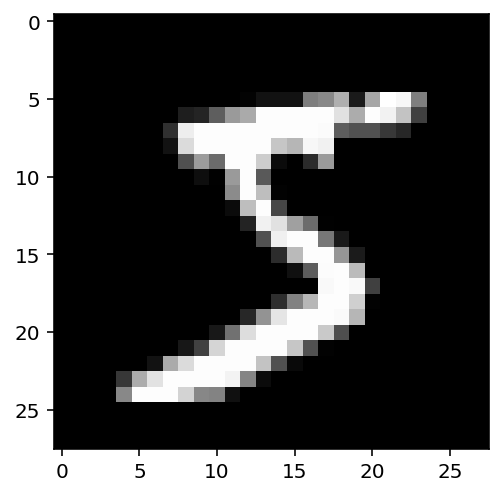

In [17]:
# Veamos una muestra
plt.imshow(x_train[0], 'gray');

In [18]:
y_train[0]

5

In [19]:
# Veamos todas las clases del conjunto de entrenamiento
set(y_train)

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9}

## Normalizamos los datos

In [20]:
#Los datos que están en el rango [0, 255] los transformamos al rango [0, 1]
x_train = x_train / 255.
x_test = x_test / 255.

In [21]:
#Los datos que están en el rango [0, 1] los transformamos al rango [-1, 1]
mean = 0.5
std = 0.5

x_train = (x_train - mean) / std
x_test = (x_test - mean) / std

## Agregamos un canal a los datos

In [22]:
x_train = x_train.reshape((-1, 28, 28, 1))
x_test = x_test.reshape((-1, 28, 28, 1))

In [23]:
x_train.shape

(60000, 28, 28, 1)

In [24]:
x_test.shape

(10000, 28, 28, 1)

## Cargamos los datos para el entrenamiento

In [25]:
#Batch size
bs = 64

In [28]:
dataset_train = tf.data.Dataset.from_tensor_slices((x_train, y_train))

dataset_train = dataset_train.shuffle(buffer_size=100).batch(bs).prefetch(50)

<PrefetchDataset shapes: ((None, 28, 28, 1), (None,)), types: (tf.float64, tf.uint8)>

In [ ]:
dataset_test = tf.data.Dataset.from_tensor_slices((x_test, y_test))

dataset_test = dataset_test.batch(bs).prefetch(50)

## Definimos un modelo

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPool2D, ReLU, Flatten, Dense
from tensorflow.keras.optimizers import SGD

def create_model():
  K.clear_session()

  input_layer = Input(shape=(28, 28, 1))
  convolutional_1 = Conv2D(16, kernel_size=3, padding="same")(input_layer)
  max_pooling_1 = MaxPool2D(2)(convolutional_1)
  relu_1 = ReLU()(max_pooling_1)
  convolutional_2 = Conv2D(32, kernel_size=3, padding="same")(relu_1)
  max_pooling_2 = MaxPool2D(2)(convolutional_2)
  relu_2 = ReLU()(max_pooling_2)
  convolutional_3 = Conv2D(64, kernel_size=3)(relu_2)
  relu_3 = ReLU()(convolutional_3)
  flatten = Flatten()(relu_3)
  dense = Dense(256, activation="relu")(flatten)
  output_layer = Dense(10, activation="softmax")(dense)

  model = Model(inputs=input_layer, outputs=output_layer)

  return model

In [ ]:
lr = 0.001
momentum = 0.9

model = create_model()

model.compile(optimizer=SGD(learning_rate=lr, momentum=momentum), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
# La función de pérdida 'sparse_categorical_crossentropy' realiza automaticamente la conversión
# del target a one-hot encoding.

In [ ]:
model.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 28, 28, 1)]       0         
_________________________________________________________________
conv2d (Conv2D)              (None, 28, 28, 16)        160       
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 14, 14, 16)        0         
_________________________________________________________________
re_lu (ReLU)                 (None, 14, 14, 16)        0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 14, 14, 32)        4640      
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 7, 7, 32)          0         
_________________________________________________________________
re_lu_1 (ReLU)               (None, 7, 7, 32)          0     

## Entrenamiento

In [ ]:
%mkdir -p my_model

In [ ]:
def show_results(log):
  val_loss = log.history['val_loss']
  val_acc = log.history['val_accuracy']
      
  fig, axes = plt.subplots(1, 2, figsize=(14,4))
  ax1, ax2 = axes
  ax1.plot(log.history['loss'], label='train')
  ax1.plot(val_loss, label='test')
  ax1.set_xlabel('epoch'); ax1.set_ylabel('loss')
  ax2.plot(log.history['accuracy'], label='train')
  ax2.plot(val_acc, label='test')
  ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy')
  for ax in axes: ax.legend()

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint_path = "my_model/model"

monitor = "val_accuracy"

mode = "max"

model_checkpoint = ModelCheckpoint(checkpoint_path, monitor=monitor, verbose=1, save_best_only=True, save_weights_only=True, mode=mode)

In [ ]:
epochs = 5

history = model.fit(dataset_train, batch_size=bs, epochs=epochs, validation_data=dataset_test, callbacks=[model_checkpoint])

Epoch 1/5
938/938 [==============================] - 43s 45ms/step - loss: 1.2513 - accuracy: 0.6396 - val_loss: 0.1633 - val_accuracy: 0.9493

Epoch 00001: val_accuracy improved from -inf to 0.94930, saving model to my_model/model
Epoch 2/5
938/938 [==============================] - 42s 45ms/step - loss: 0.1536 - accuracy: 0.9537 - val_loss: 0.0933 - val_accuracy: 0.9717

Epoch 00002: val_accuracy improved from 0.94930 to 0.97170, saving model to my_model/model
Epoch 3/5
938/938 [==============================] - 42s 45ms/step - loss: 0.0977 - accuracy: 0.9710 - val_loss: 0.0679 - val_accuracy: 0.9800

Epoch 00003: val_accuracy improved from 0.97170 to 0.98000, saving model to my_model/model
Epoch 4/5
938/938 [==============================] - 42s 45ms/step - loss: 0.0760 - accuracy: 0.9775 - val_loss: 0.0583 - val_accuracy: 0.9823

Epoch 00004: val_accuracy improved from 0.98000 to 0.98230, saving model to my_model/model
Epoch 5/5
938/938 [==============================] - 43s 46ms/s

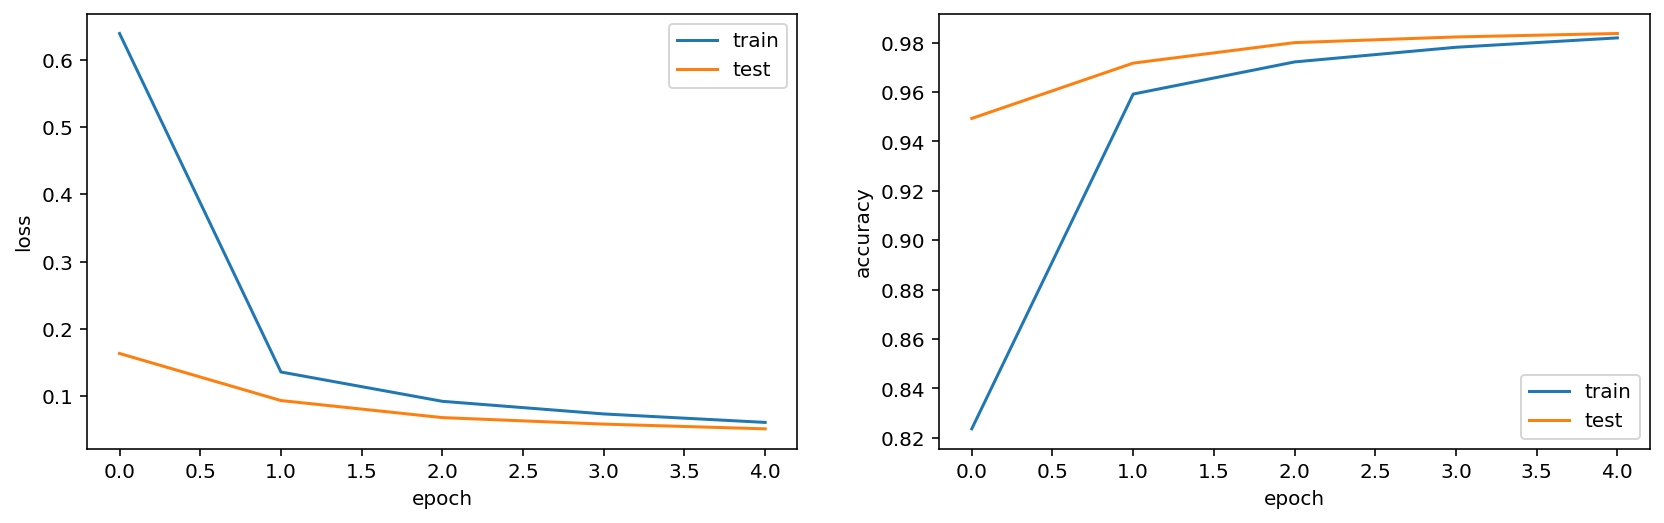

In [ ]:
show_results(history)

## Visualizando algunas predicciones

In [ ]:
batch_x_test, batch_y_test = next(iter(dataset_test))

predictions = model(batch_x_test)

In [ ]:
batch_x_test = batch_x_test.numpy()
batch_y_test = batch_y_test.numpy()
predictions = np.argmax(predictions.numpy(), axis=-1)

In [ ]:
np.random.seed(0)

random_samples_from_batch = np.random.randint(len(batch_y_test), size=5)

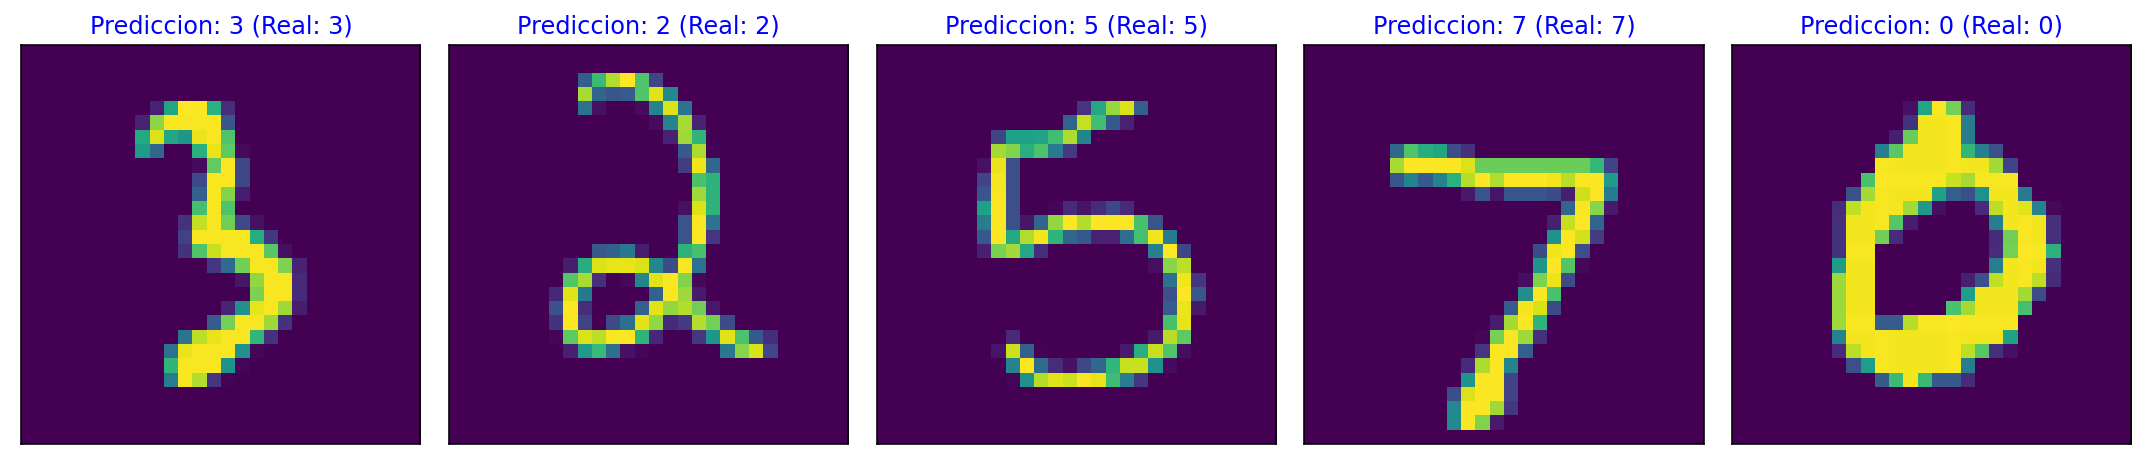

In [ ]:
figure = plt.figure(figsize=(15, 8))

for i, index in enumerate(random_samples_from_batch):
  ax = figure.add_subplot(1, 5, i + 1, xticks=[], yticks=[])
  
  image = batch_x_test[index].reshape(28, 28)
  ax.imshow(image, cmap="viridis")

  true_label = batch_y_test[index]
  predicted_label = predictions[index]
  
  condition_for_color = "blue" if predicted_label == true_label else "red"
  ax.set_title("Prediccion: {} (Real: {})".format(predicted_label, true_label),
                                                  color=(condition_for_color))

figure.tight_layout()

## Reanudamos el Entrenamiento

In [ ]:
model = create_model()

model.compile(optimizer=SGD(learning_rate=lr, momentum=momentum), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
# La función de pérdida 'sparse_categorical_crossentropy' realiza automaticamente la conversión
# del target a one-hot encoding.

In [ ]:
model.load_weights(checkpoint_path)

In [ ]:
model.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 28, 28, 1)]       0         
_________________________________________________________________
conv2d (Conv2D)              (None, 28, 28, 16)        160       
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 14, 14, 16)        0         
_________________________________________________________________
re_lu (ReLU)                 (None, 14, 14, 16)        0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 14, 14, 32)        4640      
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 7, 7, 32)          0         
_________________________________________________________________
re_lu_1 (ReLU)               (None, 7, 7, 32)          0     

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint_path = "my_model/model"

monitor = "val_accuracy"

mode = "max"

model_checkpoint = ModelCheckpoint(checkpoint_path, monitor=monitor, verbose=1, save_best_only=True, save_weights_only=True, mode=mode)

In [ ]:
epochs = 5

history = model.fit(dataset_train, batch_size=bs, epochs=epochs, validation_data=dataset_test, callbacks=[model_checkpoint])

Epoch 1/5
938/938 [==============================] - 44s 47ms/step - loss: 0.0545 - accuracy: 0.9838 - val_loss: 0.0463 - val_accuracy: 0.9845

Epoch 00001: val_accuracy improved from -inf to 0.98450, saving model to my_model/model
Epoch 2/5
938/938 [==============================] - 44s 46ms/step - loss: 0.0486 - accuracy: 0.9860 - val_loss: 0.0432 - val_accuracy: 0.9854

Epoch 00002: val_accuracy improved from 0.98450 to 0.98540, saving model to my_model/model
Epoch 3/5
938/938 [==============================] - 44s 46ms/step - loss: 0.0437 - accuracy: 0.9877 - val_loss: 0.0397 - val_accuracy: 0.9865

Epoch 00003: val_accuracy improved from 0.98540 to 0.98650, saving model to my_model/model
Epoch 4/5
938/938 [==============================] - 44s 46ms/step - loss: 0.0402 - accuracy: 0.9886 - val_loss: 0.0376 - val_accuracy: 0.9874

Epoch 00004: val_accuracy improved from 0.98650 to 0.98740, saving model to my_model/model
Epoch 5/5
938/938 [==============================] - 44s 47ms/s

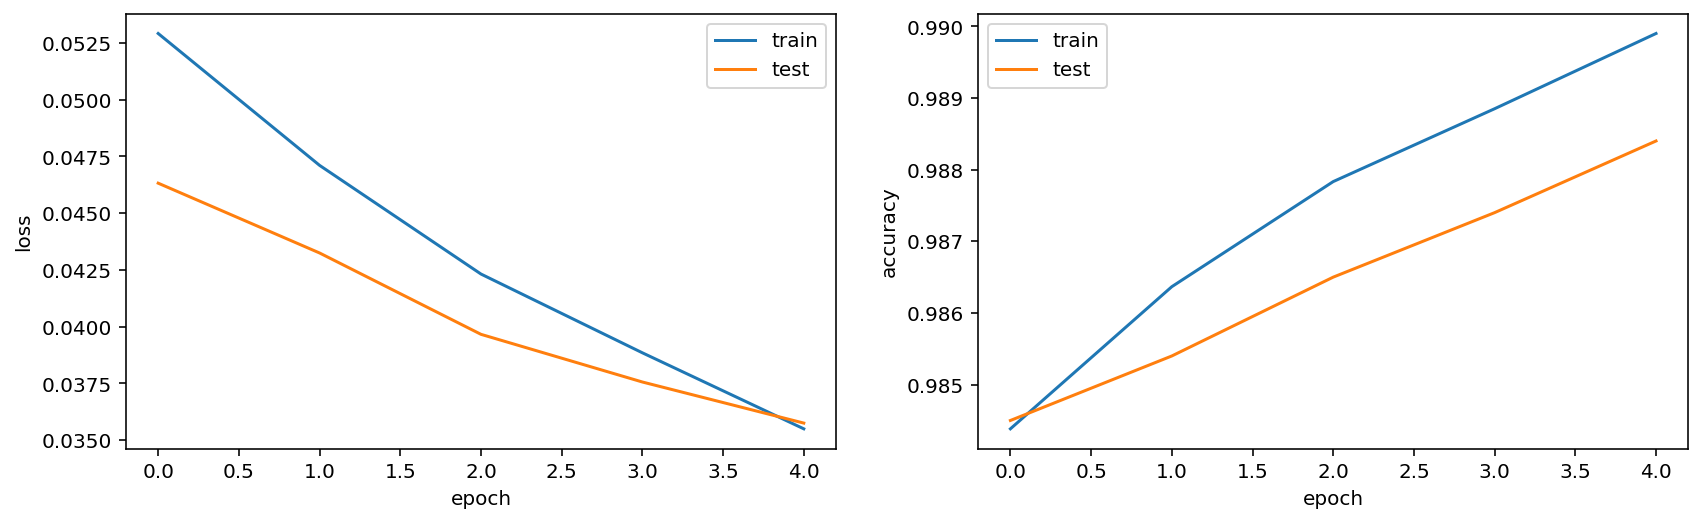

In [ ]:
show_results(history)

## Visualizando algunas predicciones

In [ ]:
batch_x_test, batch_y_test = next(iter(dataset_test))

predictions = model(batch_x_test)

In [ ]:
batch_x_test = batch_x_test.numpy()
batch_y_test = batch_y_test.numpy()
predictions = np.argmax(predictions.numpy(), axis=-1)

In [ ]:
np.random.seed(10)

random_samples_from_batch = np.random.randint(len(batch_y_test), size=5)

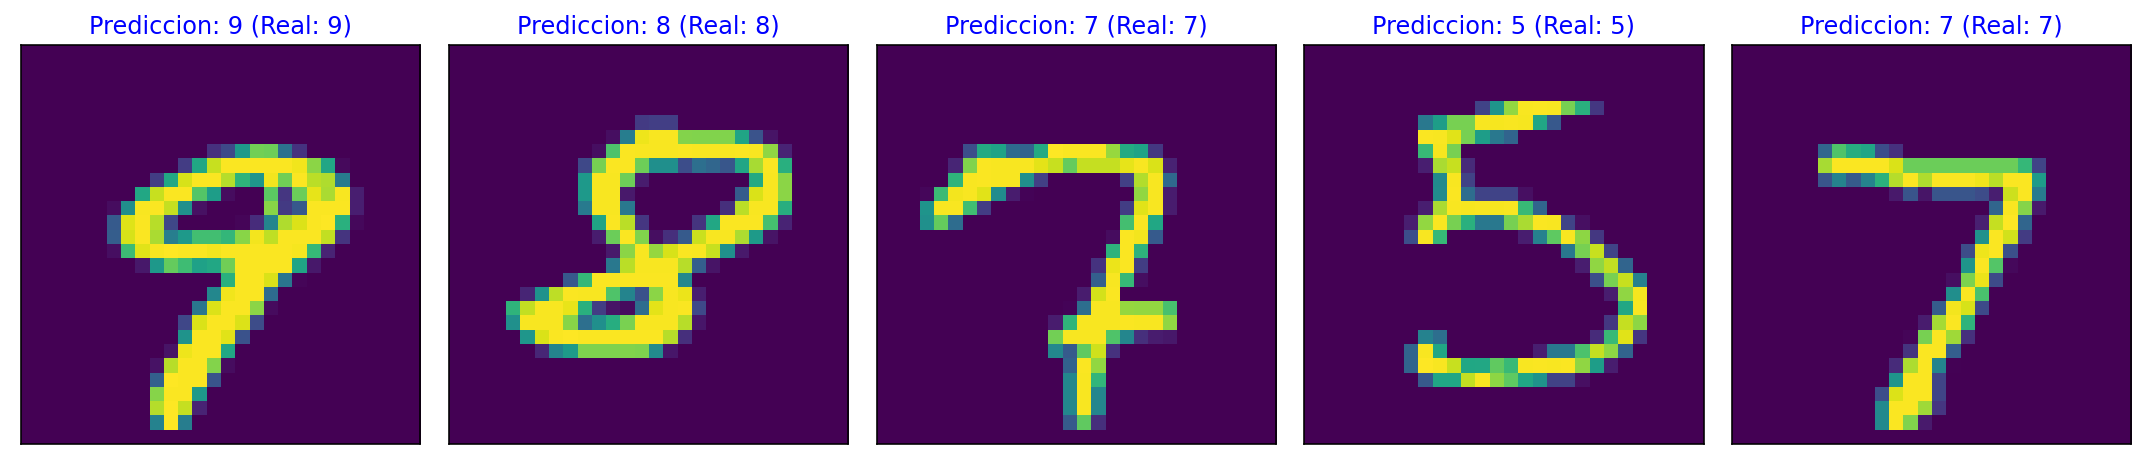

In [ ]:
figure = plt.figure(figsize=(15, 8))

for i, index in enumerate(random_samples_from_batch):
  ax = figure.add_subplot(1, 5, i + 1, xticks=[], yticks=[])
  
  image = batch_x_test[index].reshape(28, 28)
  ax.imshow(image, cmap="viridis")

  true_label = batch_y_test[index]
  predicted_label = predictions[index]
  
  condition_for_color = "blue" if predicted_label == true_label else "red"
  ax.set_title("Prediccion: {} (Real: {})".format(predicted_label, true_label),
                                                  color=(condition_for_color))

figure.tight_layout()

## Revisamos las Métricas

In [ ]:
labels = list()
predictions = list()

for batch_x_test, batch_y_test in dataset_test:
  batch_test_predictions = model(batch_x_test)
  
  batch_test_predictions = np.argmax(batch_test_predictions.numpy(), axis=-1)

  labels.append(batch_y_test)
  predictions.append(batch_test_predictions)

In [ ]:
labels = np.concatenate(labels, axis=0)
predictions = np.concatenate(predictions, axis=0)

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(labels, predictions, digits=4))

              precision    recall  f1-score   support

           0     0.9829    0.9969    0.9899       980
           1     0.9939    0.9974    0.9956      1135
           2     0.9771    0.9942    0.9856      1032
           3     0.9901    0.9931    0.9916      1010
           4     0.9929    0.9939    0.9934       982
           5     0.9877    0.9899    0.9888       892
           6     0.9968    0.9760    0.9863       958
           7     0.9892    0.9786    0.9839      1028
           8     0.9846    0.9825    0.9836       974
           9     0.9890    0.9802    0.9846      1009

    accuracy                         0.9884     10000
   macro avg     0.9884    0.9883    0.9883     10000
weighted avg     0.9884    0.9884    0.9884     10000

